In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None, "display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
from src import config as C

# 07 — Makine Öğrenmesi: Bölme, Pipeline, Baseline ve Model Karşılaştırması

**Bu notebook'un kuralı:** TEST KÜMESİNE BURADA HİÇ DOKUNMUYORUZ. Tüm karşılaştırmalar yalnızca eğitim verisinde, çapraz doğrulamayla yapılır. Test kümesi Notebook 08'de **bir kez** açılır.

## 7.1 Train / Test bölme
* `stratify=y`: churn oranı (~%8) hem eğitimde hem testte korunur. Yoksa teste hiç ayrılan müşteri düşebilir.
* `random_state=42`: tekrarlanabilirlik.
* `customer_id` ve `churn` girdi (X) değildir: ID anlamlı bir davranış değil; churn zaten hedef (X'e koyarsak *target leakage*).

In [2]:
from src.modeling import load_clean, split_data, xy
df = load_clean()
train, test = split_data(df)
X_tr, y_tr = xy(train); X_te, y_te = xy(test)
display(pd.DataFrame({"satır": [len(train), len(test)], "ayrılan": [y_tr.sum(), y_te.sum()], "churn_oranı": [y_tr.mean(), y_te.mean()]}, index=["train", "test"]))
print("Girdi sütunları:", list(X_tr.columns))

,satır,ayrılan,churn_oranı
train,1440,118,0.082
test,360,30,0.083


Girdi sütunları: ['age', 'region', 'device_type', 'plan', 'contract_type', 'tenure_months', 'monthly_usage_hours', 'monthly_fee_tl', 'discount_rate', 'payment_method', 'late_payments_6m', 'support_calls_6m', 'complaints_6m', 'satisfaction_score']


## 7.2 Ön işleme ve Pipeline — neden şart?
Model sayısal matris ister; elimizde eksikler ve metin kategoriler var. Gerekenler:

| Adım | Sınıf | Ne yapar | Neden |
|---|---|---|---|
| Özellik üretimi | `FunctionTransformer(add_features)` | Notebook 06'daki fonksiyon | API'de de aynı kod çalışsın |
| Eksik doldurma (sayısal) | `SimpleImputer("median")` | Eksiği **eğitimin** medyanıyla doldurur | Uç değerlere dayanıklı |
| Eksik doldurma (kategorik) | `SimpleImputer("most_frequent")` | En sık kategori | Basit; eksiklik bilgi taşımıyordu (NB05) |
| Ölçekleme | `StandardScaler` | $z=(x-\mu)/\sigma$ | Lojistik regresyon ölçeğe duyarlı; ağaçlar değil |
| Kodlama | `OneHotEncoder(handle_unknown="ignore")` | Kategoriyi 0/1 sütunlara açar | Eğitimde görülmeyen kategori hata vermesin |
| Birleştirme | `ColumnTransformer` | Sütun gruplarına farklı işlem | |
| Zincir | `Pipeline` | Hepsini + modeli tek nesne yapar | **Sızıntıyı önler**: CV'de her fold'da imputer/scaler yalnızca o fold'un eğitim kısmından öğrenir |

### Data Leakage (veri sızıntısı) küçük bir gösterim
Yanlış yol: medyanı **tüm veriden** hesaplayıp doldurmak; doğru yol: yalnızca eğitimden öğrenip teste uygulamak. Fark küçük görünür ama test bilgisi eğitime karışmış olur:

In [3]:
wrong = df["satisfaction_score"].median()          # tüm veri (test dahil!)
right = X_tr["satisfaction_score"].median()        # sadece eğitim
display(Markdown(f"satisfaction_score medyanı — tüm veri: **{wrong:.3f}**, yalnızca eğitim: **{right:.3f}**. Küçük fark, ama prensip: test'ten hiçbir istatistik öğrenilmemeli."))

satisfaction_score medyanı — tüm veri: **6.200**, yalnızca eğitim: **6.100**. Küçük fark, ama prensip: test'ten hiçbir istatistik öğrenilmemeli.

In [4]:
from src.preprocessing import build_pipeline, build_preprocessor
from src.features import FEATURE_SETS, SELECTED_FEATURE_SET, add_features
from sklearn.linear_model import LogisticRegression
num, cat = FEATURE_SETS[SELECTED_FEATURE_SET]
pre = build_preprocessor(True, num, cat)
Xt = pre.fit_transform(add_features(X_tr))
names = pre.get_feature_names_out()
display(Markdown(f"Dönüşüm sonrası matris: **{Xt.shape}** — sütunlar: `{list(names)}`"))
display(pd.DataFrame(Xt.toarray() if hasattr(Xt, 'toarray') else Xt, columns=names).head(4))
display(Markdown("Eğitimden öğrenilen medyanlar: " + ", ".join(f"`{c}`={v:.2f}" for c, v in zip(num, pre.named_transformers_['numeric'].named_steps['imputer'].statistics_))))

Dönüşüm sonrası matris: **(1440, 7)** — sütunlar: `['tenure_months', 'satisfaction_score', 'complaints_6m', 'support_calls_6m', 'contract_type_Annual', 'contract_type_Monthly', 'contract_type_Two-Year']`

,tenure_months,satisfaction_score,complaints_6m,support_calls_6m,contract_type_Annual,contract_type_Monthly,contract_type_Two-Year
0,-0.796,-1.696,0.862,0.615,0.000,1.000,0.000
1,0.272,-2.103,0.862,0.615,0.000,0.000,1.000
2,0.418,2.199,-0.640,-1.106,0.000,1.000,0.000
3,-0.019,-1.057,0.862,-1.106,1.000,0.000,0.000


Eğitimden öğrenilen medyanlar: `tenure_months`=38.00, `satisfaction_score`=6.10, `complaints_6m`=0.00, `support_calls_6m`=1.00

## 7.3 Baseline: "en sık sınıfı söyle"
Her model **bir referansla** kıyaslanmalı. Dummy model her müşteri için eğitimdeki oranı (~%8) tahmin eder.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from src.modeling import make_cv
dummy_major = build_pipeline(DummyClassifier(strategy="most_frequent"), False, num, cat)
r = cross_validate(dummy_major, X_tr, y_tr, cv=make_cv(), scoring=["accuracy", "recall", "precision", "roc_auc", "average_precision"], n_jobs=1)
display(pd.Series({k.replace("test_", ""): np.mean(v) for k, v in r.items() if k.startswith("test_")}, name="Dummy (most_frequent), CV").to_frame())

,"Dummy (most_frequent), CV"
accuracy,0.918
recall,0.000
precision,0.000
roc_auc,0.500
average_precision,0.082


**Okuma:** Accuracy ≈ 0,92 ama **Recall = 0**: tek bir ayrılanı bile bulamıyor. PR-AUC taban oranı (≈0,08) bize **"rastgele"nin skorunun ne olduğunu** söylüyor. Gerçek modellerimiz bunu açıkça aşmalı.

## 7.4 Model adayları
| Model | Fikir | Neden aday? | Sadelik sırası |
|---|---|---|---|
| Logistic Regression | Doğrusal sınır, olasılık verir | Hızlı, yorumlanabilir, küçük veride güçlü | 1 |
| Logistic Regression (balanced) | `class_weight="balanced"` ile azınlığa ağırlık | Dengesizliğe klasik çare | 1 |
| Decision Tree | Kurallarla dallanma | Açıklanabilir | 2 |
| Random Forest | Çok sayıda ağacın ortalaması | Doğrusal olmayan etkileşimleri yakalar | 3 |
| Hist Gradient Boosting | Ardışık ağaçlar | Genelde tablo verisinde güçlü | 4 |

Her model için **küçük bir hiperparametre ızgarası** (`GridSearchCV`) ve **5 katlı × 3 tekrarlı** stratified CV. Seçim ölçütü **PR-AUC (average precision)**.

> Hiperparametre seçimini ve model karşılaştırmasını aynı CV'de yapmak hafif iyimserdir; ama tüm modellere eşit uygulandığı için karşılaştırma adildir ve **gerçek, bağımsız not testte** gelir.

In [6]:
from src.modeling import tune_and_compare, select_by_one_se
results, tuned = tune_and_compare(X_tr, y_tr, SELECTED_FEATURE_SET)
show = results[["model", "pr_auc", "pr_auc_std", "roc_auc", "roc_auc_std", "brier", "best_params"]].copy()
display(show)

,model,pr_auc,pr_auc_std,roc_auc,roc_auc_std,brier,best_params
0,Dummy (prior),0.082,0.002,0.500,0.000,0.075,{}
1,Logistic Regression,0.267,0.067,0.748,0.050,0.069,{'C': 3}
2,Logistic Regression (balanced),0.265,0.067,0.746,0.048,0.201,{'C': 3}
3,Decision Tree,0.208,0.063,0.691,0.059,0.205,"{'max_depth': 5, 'min_samples_leaf': 20}"
4,Random Forest,0.275,0.079,0.735,0.043,0.180,"{'max_depth': 5, 'min_samples_leaf': 40}"
5,Hist Gradient Boosting,0.245,0.065,0.728,0.047,0.187,"{'max_depth': 2, 'min_samples_leaf': 40}"


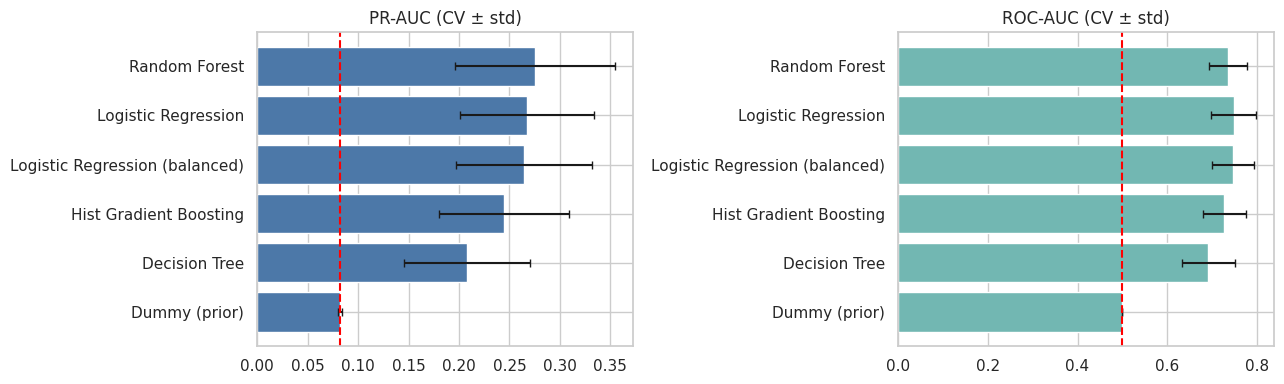

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
r = results.sort_values("pr_auc")
ax[0].barh(r["model"], r["pr_auc"], xerr=r["pr_auc_std"], color="#4c78a8", capsize=3); ax[0].axvline(y_tr.mean(), color="red", ls="--"); ax[0].set_title("PR-AUC (CV ± std)")
ax[1].barh(r["model"], r["roc_auc"], xerr=r["roc_auc_std"], color="#72b7b2", capsize=3); ax[1].axvline(0.5, color="red", ls="--"); ax[1].set_title("ROC-AUC (CV ± std)")
plt.tight_layout(); plt.show()

## 7.5 Seçim kuralı: 1-standart-hata
Skorlar birbirine çok yakın ve fold gürültüsü büyük. "En yüksek sayıyı seç" kuralı **gürültüyü ödüllendirir**. Daha sağlam kural:
1. En iyi PR-AUC'yi bul.
2. Ondan **1 standart hata** geride kalmayan tüm modelleri "eşdeğer" say.
3. Bunlar arasında **en sade** olanı seç. Sadelik eşitse **olasılıkları daha iyi kalibre olanı** (düşük Brier) seç.

In [8]:
best = results.loc[results.pr_auc.idxmax()]
se = best.pr_auc_std / np.sqrt(5)
elig = results[(results.pr_auc >= best.pr_auc - se) & (results.model != "Dummy (prior)")]
display(Markdown(f"En iyi PR-AUC: **{best.model} ({best.pr_auc:.3f})**, SE ≈ {se:.3f} → alt sınır **{best.pr_auc - se:.3f}**"))
display(elig[["model", "pr_auc", "simplicity", "brier"]])
chosen = select_by_one_se(results)
display(Markdown(f"### Seçilen model: **{chosen}**  (parametreler: `{results.loc[results.model == chosen, 'best_params'].iloc[0]}`)"))

En iyi PR-AUC: **Random Forest (0.275)**, SE ≈ 0.036 → alt sınır **0.240**

,model,pr_auc,simplicity,brier
1,Logistic Regression,0.267,1,0.069
2,Logistic Regression (balanced),0.265,1,0.201
4,Random Forest,0.275,3,0.180
5,Hist Gradient Boosting,0.245,4,0.187


### Seçilen model: **Logistic Regression**  (parametreler: `{'C': 3}`)

## 7.6 `class_weight="balanced"` ne yapar? (Kalibrasyon deneyi)
Dengesizliğe karşı en bilinen çare ağırlıklandırma. Ama bedeli var: **olasılıklar şişer.** Gerçek churn oranı %8 iken model "ortalama risk %40" demeye başlar. Sıralama aynı kalır, ama "%35 risk" sözü artık yanlıştır. Aşağıda iki lojistik modelin out-of-fold olasılıklarını karşılaştırıyoruz.

,ort. tahmin,gerçek churn oranı
ağırlıksız,0.082,0.082
balanced,0.410,0.082


İki skorun sıralama korelasyonu (Spearman): **0.997** → sıralama neredeyse aynı, **ölçek farklı**.

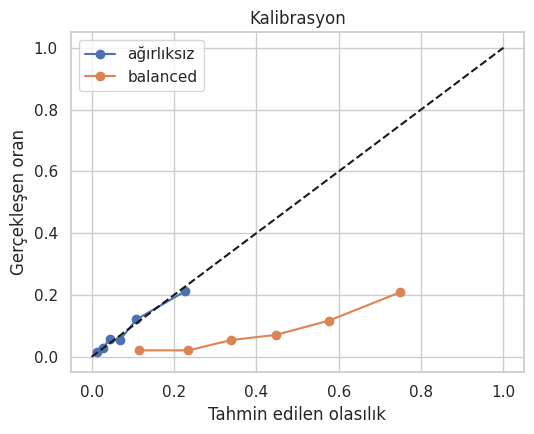

In [9]:
from src.modeling import oof_probabilities
from sklearn.calibration import calibration_curve
from scipy.stats import spearmanr
p_plain = oof_probabilities(tuned["Logistic Regression"], X_tr, y_tr, repeats=3)
p_bal = oof_probabilities(tuned["Logistic Regression (balanced)"], X_tr, y_tr, repeats=3)
display(pd.DataFrame({"ort. tahmin": [p_plain.mean(), p_bal.mean()], "gerçek churn oranı": [y_tr.mean()] * 2},
                     index=["ağırlıksız", "balanced"]))
display(Markdown(f"İki skorun sıralama korelasyonu (Spearman): **{spearmanr(p_plain, p_bal)[0]:.3f}** → sıralama neredeyse aynı, **ölçek farklı**."))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for p, lab in [(p_plain, "ağırlıksız"), (p_bal, "balanced")]:
    f, m = calibration_curve(y_tr, p, n_bins=6, strategy="quantile"); ax.plot(m, f, marker="o", label=lab)
ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("Tahmin edilen olasılık"); ax.set_ylabel("Gerçekleşen oran"); ax.legend(); ax.set_title("Kalibrasyon")
plt.tight_layout(); plt.show()

**Sonuç:** Ağırlıksız model olasılıkları gerçeğe yakın (kalibre). Dengesizliği **eşik seçimiyle** (Notebook 08) çözmek, ağırlıkla çözmekten daha temiz: hem sıralama aynı hem olasılıklar anlamlı. Karar ağacı örneği aşağıda: sığ bir ağacın kurallarını *okuyabilmek* öğretici (ama ağaç bu veride zayıf).

In [10]:
from sklearn.tree import DecisionTreeClassifier, export_text
tree = build_pipeline(DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, class_weight="balanced", random_state=C.RANDOM_STATE), False, num, cat).fit(X_tr, y_tr)
print(export_text(tree.named_steps["model"], feature_names=list(tree.named_steps["preprocessor"].get_feature_names_out()), max_depth=3))

|--- contract_type_Monthly <= 0.50
|   |--- tenure_months <= 37.50
|   |   |--- satisfaction_score <= 6.75
|   |   |   |--- class: 1
|   |   |--- satisfaction_score >  6.75
|   |   |   |--- class: 0
|   |--- tenure_months >  37.50
|   |   |--- satisfaction_score <= 5.25
|   |   |   |--- class: 0
|   |   |--- satisfaction_score >  5.25
|   |   |   |--- class: 0
|--- contract_type_Monthly >  0.50
|   |--- satisfaction_score <= 5.55
|   |   |--- complaints_6m <= 0.50
|   |   |   |--- class: 1
|   |   |--- complaints_6m >  0.50
|   |   |   |--- class: 1
|   |--- satisfaction_score >  5.55
|   |   |--- tenure_months <= 41.50
|   |   |   |--- class: 1
|   |   |--- tenure_months >  41.50
|   |   |   |--- class: 0



## 7.7 Özet — bu notebook'ta neler karar verildi?
1. Özellik seti: **core** (Notebook 06).
2. Model: **Lojistik Regresyon** (yukarıdaki kuralla; karmaşık modeller anlamlı bir kazanç sağlamadı).
3. Dengesizlik: ağırlıkla değil **eşikle** ele alınacak (kalibre olasılıklar için).
4. Test kümesi hâlâ açılmadı.